# SVM improvement

## dataset preparation

In [6]:
import pandas as pd

df = pd.read_csv('Telco-Customer-Churn.csv')

print(df.shape)
print(df.head())
print(df.describe())
print(df.info())



(7043, 21)
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        Co

In [8]:
# # Data cleaning / Feature engineering
# # 1 drop ID
# df = df.drop(columns=['customerID'])
#
# # check missing and duplicates
# # print(df.isnull().sum())
# # print(df.duplicated().sum())
# # no missing no duplicates
#
# # 2 fix TotalCharges str -> numeric and handle nan
# df['TotalCharges'] = pd.to_numeric(df['TotalCharges'].replace(r"^\s*$", pd.NA, regex=True), errors='coerce')
# df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())
#
# # 3 Encoding column for 1 and 0:
# bin_cols = [
#     "gender",
#     "Partner",
#     "Dependents",
#     "PhoneService",
#     "PaperlessBilling",
#     "Churn"
# ]
#
# for col in bin_cols:
#     if col == 'gender':
#         df[col] = df[col].map({'Female': 0, 'Male': 1})
#     else:
#         df[col] = df[col].map({'No': 0, 'Yes': 1})
#
#
# # 4 one hot encoding (multicategory columns)
# multi_cols = [
#     "MultipleLines",
#     "InternetService",
#     "OnlineSecurity",
#     "OnlineBackup",
#     "DeviceProtection",
#     "TechSupport",
#     "StreamingTV",
#     "StreamingMovies",
#     "Contract",
#     "PaymentMethod"
# ]
#
# df = pd.get_dummies(
#     df,
#     columns=multi_cols,
#     drop_first=True,
#     dtype=int,
# )

print(df.head())
print(df.shape)

   gender  SeniorCitizen  Partner  Dependents  tenure  PhoneService  \
0       0              0        1           0       1             0   
1       1              0        0           0      34             1   
2       1              0        0           0       2             1   
3       1              0        0           0      45             0   
4       0              0        0           0       2             1   

   PaperlessBilling  MonthlyCharges  TotalCharges  Churn  ...  \
0                 1           29.85         29.85      0  ...   
1                 0           56.95       1889.50      0  ...   
2                 1           53.85        108.15      1  ...   
3                 0           42.30       1840.75      0  ...   
4                 1           70.70        151.65      1  ...   

   TechSupport_Yes  StreamingTV_No internet service  StreamingTV_Yes  \
0                0                                0                0   
1                0                    

In [10]:
# # use cut method
# df['tenure_grouped'] = pd.cut(
#     df['tenure'],
#     bins=[-1, 12, 24, 48, float('inf')],
#     labels=['0-12', '13-24', '25-48', '49+']
# )

### compare kernels

In [12]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.model_selection import train_test_split


X = df.drop(columns=['Churn', 'tenure_grouped'])
y = df['Churn']


X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,stratify=y,random_state=42)

kernels = ['linear', 'poly', 'rbf']
results = []

for kernel in kernels:
    svm = SVC(kernel=kernel)
    svm.fit(X_train, y_train)

    y_pred = svm.predict(X_test)
    y_score = svm.decision_function(X_test)

    results.append({
        'Kernel': kernel,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-score': f1_score(y_test, y_pred),
        'AUC': roc_auc_score(y_test, y_score)
    })

results_df = pd.DataFrame(results)
print(results_df.round(4).to_string(index=False))

# Kernel  Accuracy  Precision  Recall  F1-score    AUC
# linear    0.7949     0.6735  0.4412    0.5331 0.8065
#   poly    0.7346     0.0000  0.0000    0.0000 0.3758
#    rbf    0.7346     0.0000  0.0000    0.0000 0.7987

# linear kernel was the best, as you ply and rbf got 0 in precision, recall and f-1 score

/Users/hofman/Documents/najot_talim/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


Kernel  Accuracy  Precision  Recall  F1-score    AUC
linear    0.7949     0.6735  0.4412    0.5331 0.8065
  poly    0.7346     0.0000  0.0000    0.0000 0.3758
   rbf    0.7346     0.0000  0.0000    0.0000 0.7987


/Users/hofman/Documents/najot_talim/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


## Tune C and gamma using GridSearchCV

In [13]:
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC

param_grid = {
    'C': [0.1, 1, 10, 100],
    'gamma': [0.01, 0.1, 1]
}

svm = SVC(kernel='rbf')

grid_search = GridSearchCV(
    svm,
    param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best CV F1-score:", round(grid_search.best_score_, 4))

# Best parameters: {'C': 10, 'gamma': 0.01}
# Best CV F1-score: 0.481

Best parameters: {'C': 10, 'gamma': 0.01}
Best CV F1-score: 0.481


### visual using heatmap

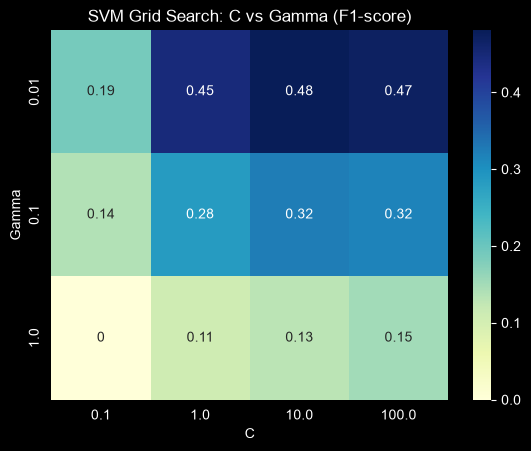

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt

results = pd.DataFrame(grid_search.cv_results_)

heatmap_data = results.pivot(
    index='param_gamma',
    columns='param_C',
    values='mean_test_score'
)

sns.heatmap(heatmap_data, annot=True, cmap='YlGnBu')

plt.title('SVM Grid Search: C vs Gamma (F1-score)')
plt.xlabel('C')
plt.ylabel('Gamma')
plt.show()

## Weight of each class

In [17]:
models = {
    'Without class_weight': SVC(kernel='rbf'),
    'With balanced weights': SVC(kernel='rbf', class_weight='balanced')
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    results.append({
        'Model': name,
        'Churn Precision': precision_score(y_test, y_pred, pos_label=1),
        'Churn Recall': recall_score(y_test, y_pred, pos_label=1),
        'Churn F1-score': f1_score(y_test, y_pred, pos_label=1)
    })

results_df = pd.DataFrame(results)
print(results_df.round(4).to_string(index=False))
#    Model  Churn Precision  Churn Recall  Churn F1-score
#  Without class_weight           0.0000        0.0000          0.0000
# With balanced weights           0.4178        0.5909          0.4895

# class weight siz it couldnt identify everything is 0.

/Users/hofman/Documents/najot_talim/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


                Model  Churn Precision  Churn Recall  Churn F1-score
 Without class_weight           0.0000        0.0000          0.0000
With balanced weights           0.4178        0.5909          0.4895
